# Clase 05 — ¿Cómo escucha un Transformer?

## Del sonido al espectrograma, de los parches a la atención

**ACUS220 — Acústica Computacional con Python · Universidad Austral de Chile**  
**Actividad:** jueves 5 de noviembre de 2026 · **Duración sugerida:** 70–80 minutos

> **Nuestra pregunta:** si dos grabaciones contienen los mismos sonidos, pero en distinto orden, ¿cómo podría un modelo distinguir lo que ocurrió?

Hoy conoceremos las ideas fundamentales del **Audio Spectrogram Transformer (AST)** mediante un experimento acústico que podemos **escuchar, visualizar y discutir**. Empezaremos por el panorama general del modelo y después descubriremos cada pieza. No entrenaremos redes neuronales ni descargaremos modelos grandes.

**Al terminar, podrás:**

1. Escuchar dos escenas y reconocer que **identidad acústica** y **orden temporal** no son lo mismo.
2. Interpretar un mapa de energía log-Mel y explicar qué es un **parche espectrotemporal**.
3. Diferenciar un parche, un *embedding* con posición y un **Transformer encoder**.
4. Explicar intuitivamente la **autoatención** y el recorrido hasta los puntajes de clasificación.
5. Distinguir la **actividad sonora**, el **silencio del archivo** y el **padding** de entrada.

**Ruta de la actividad:** orientarnos → escuchar → observar → dividir → representar → relacionar → cuestionar.


## 0. Preparamos nuestro cuaderno

Usaremos bibliotecas conocidas del curso: **NumPy**, **Matplotlib**, **Librosa** e **IPython**. Todas las señales se generan localmente.

> **Importante:** los resultados que veremos serán de un laboratorio didáctico. No son predicciones de un modelo AST entrenado.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
from matplotlib.patches import Rectangle
from IPython.display import Audio, display

SR = 16_000  # 16 kHz: frecuencia de muestreo usada por configuraciones habituales de AST
SEMILLA = 220
np.random.seed(SEMILLA)

print('NumPy:', np.__version__)
print('Librosa:', librosa.__version__)
print('Frecuencia de muestreo:', SR, 'Hz')

NumPy: 2.5.3
Librosa: 1.0.0
Frecuencia de muestreo: 16000 Hz


### 0.1. Primero, el mapa completo: ¿qué es AST?

Un **Audio Spectrogram Transformer (AST)** es una arquitectura para **clasificación de audio**. Su punto de partida para el modelo es un **espectrograma log-Mel**, no la forma de onda directamente: primero calculamos esa representación a partir de la señal.

- **Parches:** pequeñas regiones del espectrograma con información local de tiempo y frecuencia.
- **Embeddings:** vectores obtenidos al proyectar esos parches; se incorpora información sobre su **posición**, para no perder dónde estaban.
- **Transformer:** arquitectura que transforma conjuntamente una secuencia de representaciones mediante varias capas. Cada bloque combina **autoatención** con otras operaciones, entre ellas una red neuronal de tipo *feed-forward*.
- **Autoatención:** mecanismo por el que la representación de un parche puede **combinar información de otros parches**, con pesos calculados a partir de las representaciones. **No equivale automáticamente a explicar una decisión**.

**La pregunta clave:** ¿cómo pasamos de una región del espectrograma a una decisión sobre el sonido completo? Observa el recorrido antes de estudiar cada etapa.

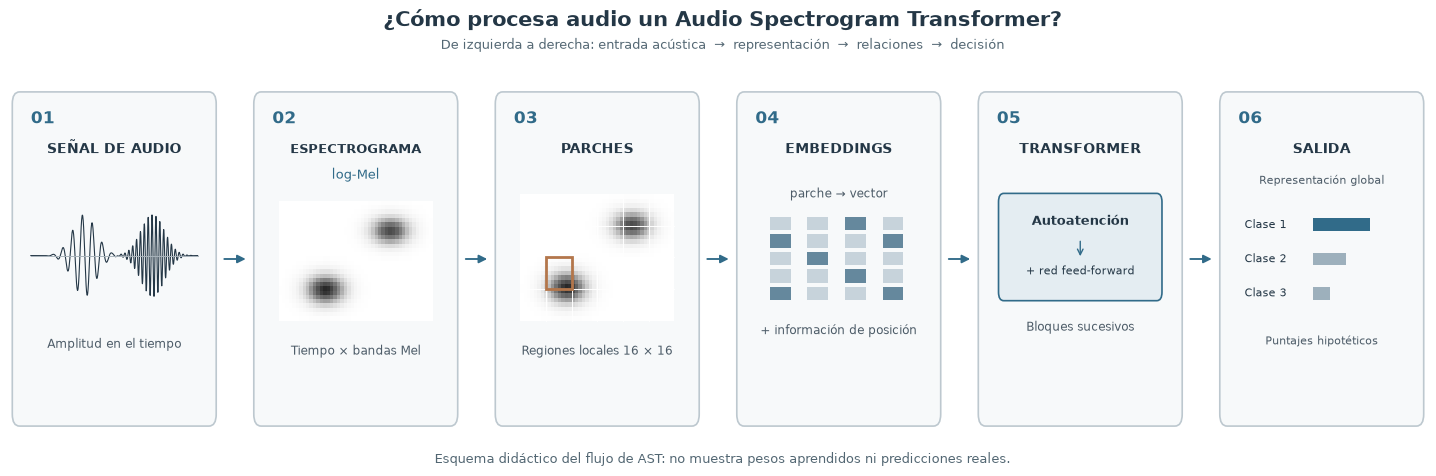

In [5]:
# FIGURA DE ORIENTACIÓN. Dibujo conceptual con Matplotlib: NO ejecuta AST.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

FIG_FONDO = '#ffffff'
TINTA = '#243746'
ACENTO = '#316b89'
ACENTO_2 = '#b3764b'
BORDE = '#bdc8cf'

fig = plt.figure(figsize=(15, 5.1), facecolor=FIG_FONDO)
fig.suptitle('¿Cómo procesa audio un Audio Spectrogram Transformer?',
             fontsize=15, weight='bold', color=TINTA, y=0.975)
fig.text(0.5, 0.897, 'De izquierda a derecha: entrada acústica  →  representación  →  relaciones  →  decisión',
         fontsize=9.5, ha='center', color='#536773')

# Una fila de seis escenas dibujadas en ejes independientes para conservar su legibilidad.
lefts = [0.025 + i * 0.161 for i in range(6)]
width = 0.139
axs = []
for i, x_left in enumerate(lefts):
    ax = fig.add_axes([x_left, 0.15, width, 0.67])
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    card = FancyBboxPatch((0.025, 0.025), 0.95, 0.95,
                          boxstyle='round,pad=0.014,rounding_size=0.035',
                          facecolor='#f7f9fa', edgecolor=BORDE, linewidth=1.2,
                          transform=ax.transAxes)
    ax.add_patch(card)
    ax.text(0.10, 0.91, f'{i + 1:02d}', weight='bold', color=ACENTO,
            fontsize=12, va='center', transform=ax.transAxes)
    axs.append(ax)

# 1. Audio: dos eventos con distinta frecuencia, mismo orden de visualización.
ax = axs[0]
ax.text(0.5, 0.81, 'SEÑAL DE AUDIO', ha='center', weight='bold', fontsize=10, color=TINTA)
mini_t = np.linspace(0, 1, 750)
mini_a = np.exp(-((mini_t - 0.32)/0.10)**2) * np.sin(2*np.pi*17*mini_t)
mini_b = np.exp(-((mini_t - 0.73)/0.10)**2) * np.sin(2*np.pi*43*mini_t)
ax.plot(0.10 + mini_t*0.80, 0.51 + 0.12*(mini_a + mini_b),
        color=TINTA, lw=0.8)
ax.plot([0.10,0.90],[0.51,0.51],color='#a8b3bb',lw=0.7)
ax.text(0.5, 0.24, 'Amplitud en el tiempo', ha='center', fontsize=8.5, color='#4d5c68')

# 2. Log-Mel: schematic frequency vs time energy patches.
ax = axs[1]
ax.text(0.5, 0.81, 'ESPECTROGRAMA', ha='center', weight='bold', fontsize=9.6, color=TINTA)
ax.text(0.5, 0.735, 'log-Mel', ha='center', fontsize=9, color=ACENTO)
x = np.linspace(0,1,45); y = np.linspace(0,1,28)
X,Y = np.meshgrid(x,y)
example = (np.exp(-((X-.3)/.13)**2 - ((Y-.25)/.13)**2) +
           .9*np.exp(-((X-.73)/.13)**2 - ((Y-.76)/.12)**2))
ax.imshow(example, extent=(.13,.87,.32,.67), origin='lower', cmap='Greys',
          aspect='auto', interpolation='nearest', vmin=0, vmax=1.15, zorder=2)
ax.text(.5,.22,'Tiempo × bandas Mel',ha='center',fontsize=8.5,color='#4d5c68')

# 3. Grilla de parches sobre un espectrograma esquemático.
ax=axs[2]
ax.text(0.5, 0.81, 'PARCHES', ha='center', weight='bold', fontsize=10, color=TINTA)
ax.imshow(example, extent=(.13,.87,.32,.69), origin='lower', cmap='Greys',
          aspect='auto', interpolation='nearest', vmin=0, vmax=1.15, zorder=2)
for i in range(1,6):
    xx=.13+i*(.74/6)
    ax.plot([xx,xx],[.32,.69],color='white',lw=.7,zorder=3)
for i in range(1,4):
    yy=.32+i*(.37/4)
    ax.plot([.13,.87],[yy,yy],color='white',lw=.7,zorder=3)
ax.add_patch(Rectangle((.13+.74/6*1,.32+.37/4*1),.74/6,.37/4,
                       linewidth=2,edgecolor=ACENTO_2,facecolor='none',zorder=4))
ax.text(.5,.22,'Regiones locales 16 × 16',ha='center',fontsize=8.3,color='#4d5c68')

# 4. La proyección y el agregado de posición, tokens esquemáticos.
ax=axs[3]
ax.text(0.5, 0.81, 'EMBEDDINGS', ha='center', weight='bold', fontsize=10, color=TINTA)
for j in range(4):
    xj=.17+j*.18
    for k in range(5):
        ax.add_patch(Rectangle((xj,.38+k*.051),.10,.039,
                     facecolor=('#65889d' if (j+k)%3==0 else '#c7d3db'),
                     edgecolor='none'))
ax.text(.50,.68,'parche → vector',ha='center',fontsize=8.7,color='#4d5c68')
ax.text(.50,.28,'+ información de posición',ha='center',fontsize=8.4,color='#4d5c68')

# 5. Atencion vive DENTRO del Transformer (no un bloque posterior).
ax=axs[4]
ax.text(0.50, 0.81, 'TRANSFORMER', ha='center', weight='bold', fontsize=10, color=TINTA)
ax.add_patch(FancyBboxPatch((.12,.39),.76,.29,boxstyle='round,pad=.012,rounding_size=.025',
                            facecolor='#e4edf2',edgecolor=ACENTO,linewidth=1.2))
ax.text(.50,.60,'Autoatención',ha='center',fontsize=9.5,weight='bold',color=TINTA)
ax.annotate('',xy=(.50,.50),xytext=(.50,.56),arrowprops=dict(arrowstyle='->',color=ACENTO))
ax.text(.50,.455,'+ red feed-forward',ha='center',fontsize=8.2,color=TINTA)
ax.text(.50,.29,'Bloques sucesivos',ha='center',fontsize=8.5,color='#4d5c68')

# 6. Scores: hypothetical output, not a trained model.
ax=axs[5]
ax.text(.5,.81,'SALIDA',ha='center',weight='bold',fontsize=10,color=TINTA)
ax.text(.5,.72,'Representación global',ha='center',fontsize=8.1,color='#4d5c68')
for yi, score, label in [(0.60,.68,'Clase 1'),(0.50,.39,'Clase 2'),(0.40,.20,'Clase 3')]:
    ax.text(.13,yi,label,fontsize=7.8,color=TINTA,va='center')
    ax.add_patch(Rectangle((.46,yi-.019),score*.40,.038,
                 color=ACENTO if label=='Clase 1' else '#9db0bc',ec='none'))
ax.text(.5,.25,'Puntajes hipotéticos',ha='center',fontsize=8.2,color='#4d5c68')

# Flechas dibujadas en el espacio de la figura: el flujo atraviesa los seis pasos.
for i in range(5):
    start=(lefts[i]+width+.002,.485)
    end=(lefts[i+1]-.002,.485)
    arr=FancyArrowPatch(start,end,transform=fig.transFigure,arrowstyle='-|>',
                        mutation_scale=12,lw=1.35,color=ACENTO,clip_on=False)
    fig.add_artist(arr)
fig.text(.5,.085,
         'Esquema didáctico del flujo de AST: no muestra pesos aprendidos ni predicciones reales.',
         ha='center',fontsize=9,color='#536773')
plt.show()

**Figura 1.** Panorama conceptual de AST. El sonido se convierte en una representación log-Mel; esta se divide en parches, se proyecta a *embeddings* con información de posición y pasa por bloques Transformer que incluyen **autoatención**. La salida de una representación global alimenta un clasificador. **Las barras finales son ilustrativas: no proceden de un modelo ejecutado.**

> **Para recordar:** el **Transformer** es la arquitectura; la **autoatención** es uno de sus mecanismos internos. Un peso de atención no es, por sí solo, una explicación de la predicción.

**Antes de continuar:** ¿por qué sería útil conservar la *posición temporal* de cada parche si vamos a comparar dos sonidos con el mismo contenido, pero en distinto orden?

Ahora sí, empecemos por escuchar los sonidos.

## 1. Primero escuchamos: A–B y B–A

Imagina dos sonidos:

- **A:** un tono relativamente grave.
- **B:** un tono relativamente agudo.

Construiremos dos escenas con **los mismos eventos**, la misma amplitud y la misma duración; cambia únicamente el orden. Para simplificar, usaremos sonidos sintéticos y separados en el tiempo.

**Antes de mirar los espectrogramas:** escucha ambas escenas. ¿Sientes que son la misma secuencia? ¿Qué información necesitaría un computador para distinguirlas?

In [6]:
DURACION = 2.4  # segundos
N = int(DURACION * SR)

def evento_tonal(f0, duracion=0.58):
    """Tono con dos armónicos y envolvente suave; sin archivos externos."""
    t = np.arange(int(duracion * SR)) / SR
    envolvente = np.sin(np.pi * np.linspace(0, 1, len(t))) ** 2
    onda = np.sin(2 * np.pi * f0 * t) + 0.22 * np.sin(2 * np.pi * 2 * f0 * t)
    return 0.22 * envolvente * onda

A = evento_tonal(330)
B = evento_tonal(880)

def escena(primero, segundo):
    x = np.zeros(N, dtype=np.float32)
    for inicio, sonido in [(0.25, primero), (1.25, segundo)]:
        i = int(inicio * SR)
        x[i:i+len(sonido)] += sonido.astype(np.float32)
    return x

x_ab = escena(A, B)
x_ba = escena(B, A)

print('Escena A → B')
display(Audio(x_ab, rate=SR))
print('Escena B → A')
display(Audio(x_ba, rate=SR))

Escena A → B


Escena B → A


**Preguntas de escucha:** ¿cuál tiene primero el sonido grave? ¿Pueden distinguirse escuchando únicamente uno de los eventos, o hace falta observar su **relación temporal**?

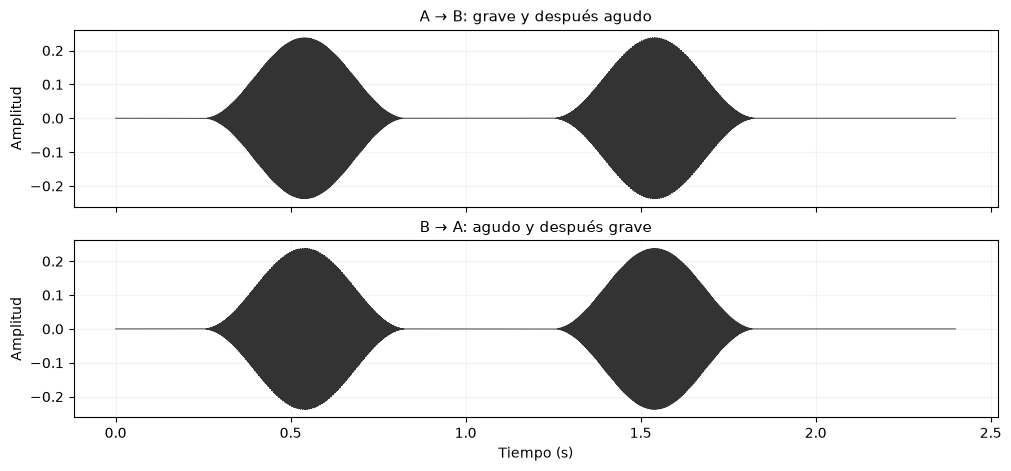

In [7]:
t = np.arange(N) / SR
fig, ax = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, constrained_layout=True)
for eje, x, titulo in zip(ax, [x_ab, x_ba], ['A → B: grave y después agudo', 'B → A: agudo y después grave']):
    eje.plot(t, x, linewidth=0.65, color='0.2')
    eje.set_ylabel('Amplitud')
    eje.set_title(titulo, fontsize=11)
    eje.grid(alpha=0.15)
ax[-1].set_xlabel('Tiempo (s)')
plt.show()

## 2. De la onda a un mapa de energía: espectrograma log-Mel

La señal de audio es una colección de valores en el tiempo. En cambio, un **espectrograma** nos ayuda a ver **cuándo** aparece energía en distintas regiones de frecuencia.

Primero calculamos una transformada de Fourier en ventanas cortas; después agrupamos su energía mediante filtros **Mel** y aplicamos una transformación logarítmica.

Para nuestra demostración:

- Frecuencia de muestreo: **16 000 Hz**.
- Ventana: **25 ms** (400 muestras).
- Salto entre ventanas: **10 ms** (160 muestras).
- Número de bandas Mel: **128**.

Estas elecciones son cercanas a las usadas en AST. **Nuestra implementación con Librosa no reproduce exactamente el extractor Kaldi/fbank utilizado en las implementaciones habituales de AST.** Sirve para comprender y visualizar el principio.

> Pregunta: ¿por qué no bastaría con usar el espectro promedio de toda la grabación para distinguir A–B de B–A?

log-Mel A–B: (128, 238) (bandas Mel × cuadros temporales)
log-Mel B–A: (128, 238)


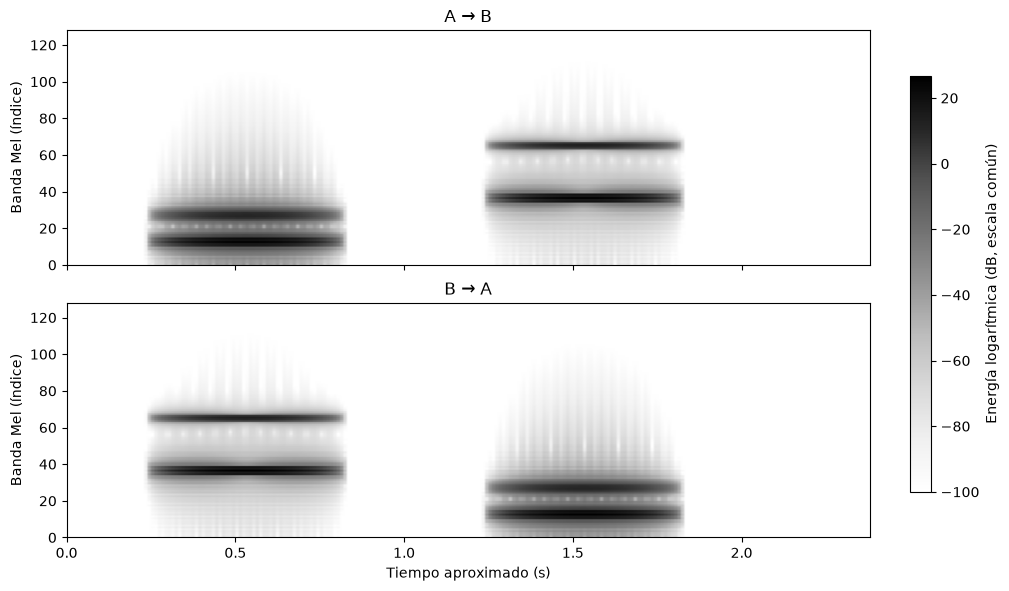

In [8]:
N_FFT = 400
HOP = 160
N_MELS = 128

def calcular_logmel(x):
    # Ventanas deslizantes de 25 ms, cada 10 ms (FFT educativa con NumPy).
    tramas = np.lib.stride_tricks.sliding_window_view(x, N_FFT)[::HOP]
    ventanas = tramas * np.hanning(N_FFT)[None, :]
    potencia_fft = np.abs(np.fft.rfft(ventanas, axis=-1)) ** 2
    # Banco triangular Mel; esta versión didáctica no es el fbank Kaldi exacto.
    filtros_mel = librosa.filters.mel(
        sr=SR, n_fft=N_FFT, n_mels=N_MELS,
        fmin=20, fmax=SR / 2, norm=None,
    )
    potencia_mel = (potencia_fft @ filtros_mel.T).T
    logmel = 10 * np.log10(np.maximum(potencia_mel, 1e-10))
    return potencia_mel, logmel

mel_ab, logmel_ab = calcular_logmel(x_ab)
mel_ba, logmel_ba = calcular_logmel(x_ba)
print('log-Mel A–B:', logmel_ab.shape, '(bandas Mel × cuadros temporales)')
print('log-Mel B–A:', logmel_ba.shape)

lo = min(logmel_ab.min(), logmel_ba.min())
hi = max(logmel_ab.max(), logmel_ba.max())
fig, axes = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True, constrained_layout=True)
for eje, datos, titulo in zip(axes, [logmel_ab, logmel_ba], ['A → B', 'B → A']):
    im = eje.imshow(datos, origin='lower', aspect='auto', cmap='Greys',
                    extent=(0, datos.shape[1] * HOP/SR, 0, N_MELS), vmin=lo, vmax=hi)
    eje.set_ylabel('Banda Mel (índice)')
    eje.set_title(titulo)
axes[-1].set_xlabel('Tiempo aproximado (s)')
fig.colorbar(im, ax=axes, shrink=0.82, label='Energía logarítmica (dB, escala común)')
plt.show()

**Lectura acústica:** la posición horizontal representa el tiempo y la vertical representa las bandas Mel (no es una escala lineal de Hz). Los tonos cambian de posición en el eje de frecuencia cuando invertimos el orden, aunque los eventos sean los mismos.

## 3. ¿Por qué dividir un espectrograma en parches?

AST toma el espectrograma como una representación bidimensional y lo divide en **parches pequeños**. En la configuración original habitual, cada parche contiene **16 bandas × 16 cuadros** y los parches consecutivos pueden **solaparse**: el salto suele ser de 10 bandas o 10 cuadros.

Imagina una hoja cuadriculada: cada ventana conserva un pedazo local del sonido, pero necesitamos relacionar muchos pedazos para comprender una escena completa.

**Importante:** el área temporal de un parche no es exactamente un segmento aislado de audio; contiene cuadros espectrales calculados mediante ventanas que también se solapan.

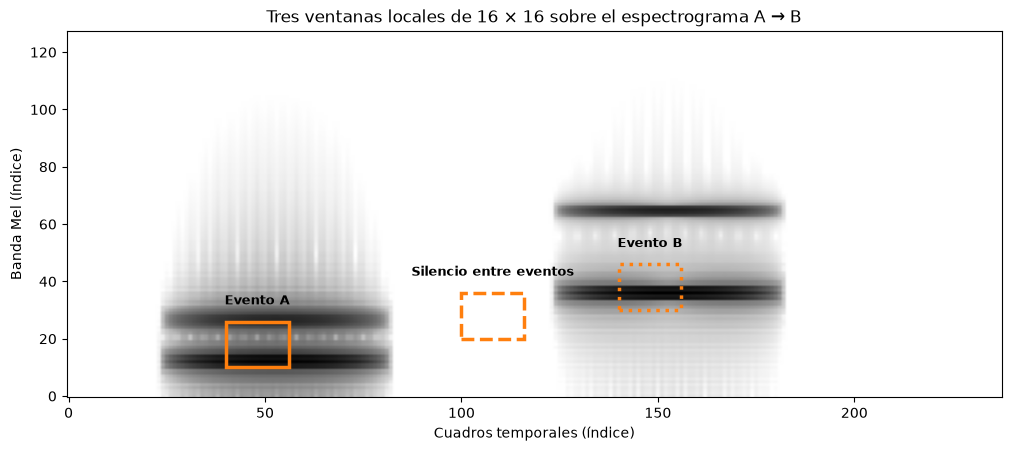

In [9]:
LADO = 16
PASO = 10

def coordenada_parche(t_segundos, datos_potencia):
    """Selecciona una ventana 16×16 cercana a una posición temporal."""
    j0 = (int(t_segundos * SR / HOP) // PASO) * PASO
    j0 = min(j0, datos_potencia.shape[1] - LADO)
    f_mas_fuerte = np.argmax(datos_potencia[:, j0:j0+LADO].mean(axis=1))
    i0 = min((int(f_mas_fuerte) // PASO) * PASO, N_MELS - LADO)
    return i0, j0

parches_ejemplo = [
    ('Evento A', *coordenada_parche(0.44, mel_ab)),
    ('Silencio entre eventos', 20, (int(1.0 * SR / HOP)//PASO)*PASO),
    ('Evento B', *coordenada_parche(1.47, mel_ab)),
]

fig, eje = plt.subplots(figsize=(10, 4.4), constrained_layout=True)
eje.imshow(logmel_ab, origin='lower', aspect='auto', cmap='Greys', vmin=lo, vmax=hi)
estilos = ['solid', 'dashed', 'dotted']
for (etiqueta, i0, j0), estilo in zip(parches_ejemplo, estilos):
    eje.add_patch(Rectangle((j0, i0), LADO, LADO, fill=False,
                            edgecolor='tab:orange', linewidth=2.5, linestyle=estilo))
    eje.annotate(etiqueta, (j0 + LADO/2, i0 + LADO + 6),
                 ha='center', fontsize=9, fontweight='bold')
eje.set_xlabel('Cuadros temporales (índice)')
eje.set_ylabel('Banda Mel (índice)')
eje.set_title('Tres ventanas locales de 16 × 16 sobre el espectrograma A → B')
plt.show()

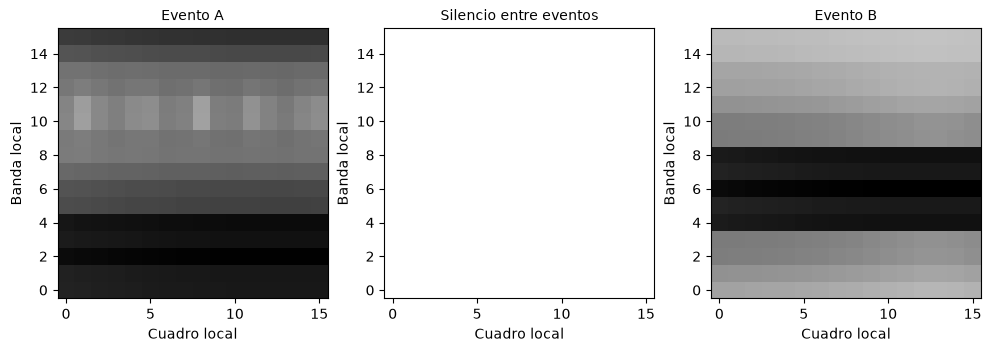

Cantidad de parches: 276
Forma de cada parche: (16, 16)
Con 16×16 valores, cada parche contiene 256 números.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(9.8, 3.3), constrained_layout=True)
for eje, (etiqueta, i0, j0) in zip(axes, parches_ejemplo):
    parche = logmel_ab[i0:i0+LADO, j0:j0+LADO]
    eje.imshow(parche, origin='lower', aspect='equal', cmap='Greys', vmin=lo, vmax=hi)
    eje.set_title(etiqueta, fontsize=10)
    eje.set_xlabel('Cuadro local')
    eje.set_ylabel('Banda local')
plt.show()

inicios_f = range(0, N_MELS - LADO + 1, PASO)
inicios_t = range(0, logmel_ab.shape[1] - LADO + 1, PASO)
parches = np.stack([logmel_ab[i:i+LADO, j:j+LADO]
                    for i in inicios_f for j in inicios_t])
print('Cantidad de parches:', len(parches))
print('Forma de cada parche:', parches.shape[1:])
print('Con 16×16 valores, cada parche contiene', LADO*LADO, 'números.')

## 4. Un parche no es todavía un *embedding*

Podemos **aplanar** un parche de 16 × 16 valores hasta obtener un vector de **256 números**. Después, AST aplica una **proyección cuyos parámetros se aprenden** durante el entrenamiento. Así convierte cada parche en un *embedding*, es decir, una representación numérica que el modelo puede procesar.

En una configuración AST base, los embeddings tienen habitualmente **768 componentes**. Para que nuestro ejercicio sea pequeño, usaremos **8 componentes** y una proyección **aleatoria**, solo como ilustración matemática: **no es un embedding aprendido por AST**.

AST también utiliza información sobre la **posición** de los parches. Si ignoráramos por completo su ubicación temporal, sería difícil diferenciar A–B de B–A.

Matriz de parches aplanados: (276, 256)
Matriz de proyección didáctica: (256, 8)
Vectores resultantes: (276, 8)


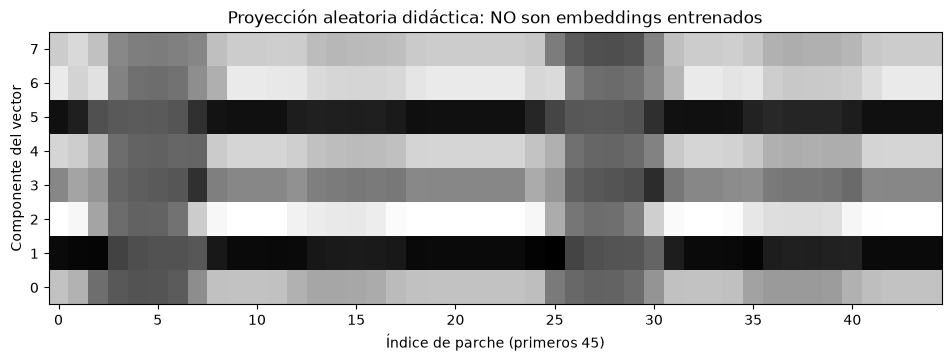

In [11]:
vector_parche = parches.reshape(len(parches), -1)
rng = np.random.default_rng(SEMILLA)
W_ejemplo = rng.standard_normal((LADO*LADO, 8)) / np.sqrt(LADO*LADO)
embeddings_didacticos = vector_parche @ W_ejemplo

print('Matriz de parches aplanados:', vector_parche.shape)
print('Matriz de proyección didáctica:', W_ejemplo.shape)
print('Vectores resultantes:', embeddings_didacticos.shape)

fig, eje = plt.subplots(figsize=(9.4, 3.5), constrained_layout=True)
eje.imshow(embeddings_didacticos[:45].T, aspect='auto', origin='lower', cmap='Greys')
eje.set_xlabel('Índice de parche (primeros 45)')
eje.set_ylabel('Componente del vector')
eje.set_yticks(range(8))
eje.set_title('Proyección aleatoria didáctica: NO son embeddings entrenados')
plt.show()

## 5. La idea de atención: cada parche puede consultar a otros

Piensa en una grabación donde oímos un golpe, una pausa y después un motor. Para identificar una escena, quizá no baste con mirar un instante: necesitamos **relacionar** regiones que están separadas en el tiempo.

Un mecanismo de atención asigna pesos a la información procedente de distintos parches. En los Transformers reales, estas relaciones se calculan mediante representaciones llamadas *queries*, *keys* y *values* (consultas, claves y valores), con parámetros aprendidos.

En forma simplificada:

$$
\mathrm{Atencion}(Q,K,V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right)V.
$$

En lugar de memorizar la expresión, recuerda dos ideas: **comparar** representaciones y **ponderar** qué información combinar.

El siguiente experimento usa tres vectores ilustrativos y **no** son pesos de atención de una red AST.

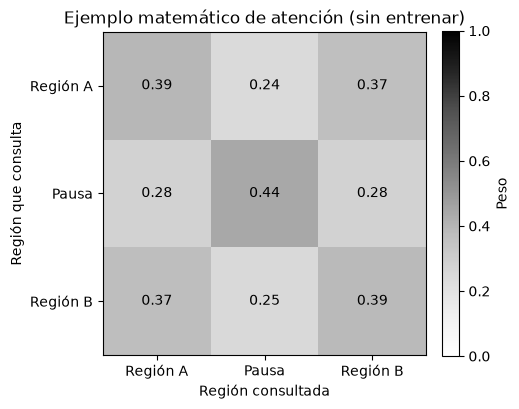

Suma de cada fila: [1. 1. 1.]
Representación combinada (3 regiones × 3 componentes): (3, 3)


In [12]:
# Ejemplo transparente: vectores ficticios que simbolizan tres regiones del sonido.
# La atención aquí se calcula sin entrenamiento ni pesos AST.
nombres = ['Región A', 'Pausa', 'Región B']
X = np.array([
    [1.0, 0.1, 0.2],  # región A
    [0.1, 1.0, 0.1],  # pausa
    [0.8, 0.1, 0.6],  # región B: algo parecido a A, pero no idéntica
])
Q = X
K = X
V = X
scores = Q @ K.T / np.sqrt(X.shape[1])
scores_estables = scores - scores.max(axis=1, keepdims=True)
exp_scores = np.exp(scores_estables)
pesos = exp_scores / exp_scores.sum(axis=1, keepdims=True)
resultado = pesos @ V

fig, eje = plt.subplots(figsize=(5, 4), constrained_layout=True)
im = eje.imshow(pesos, cmap='Greys', vmin=0, vmax=1)
eje.set_xticks(range(3), nombres)
eje.set_yticks(range(3), nombres)
eje.set_xlabel('Región consultada')
eje.set_ylabel('Región que consulta')
eje.set_title('Ejemplo matemático de atención (sin entrenar)')
for i in range(3):
    for j in range(3):
        eje.text(j, i, f'{pesos[i,j]:.2f}', ha='center', va='center',
                 color='white' if pesos[i,j] > 0.5 else 'black')
fig.colorbar(im, ax=eje, label='Peso')
plt.show()
print('Suma de cada fila:', pesos.sum(axis=1).round(3))
print('Representación combinada (3 regiones × 3 componentes):', resultado.shape)

**Discusión:** ¿todos los parches deberían atender por igual a todos los demás? ¿Por qué importaría la posición si intercambiamos el orden de dos eventos?

> **Precaución científica:** una matriz de atención no demuestra por sí sola qué información fue utilizada causalmente para tomar una decisión. Aquí solo ilustramos cómo se combinan representaciones.

## 6. ¿Cómo llega AST a reconocer un sonido?

Retomemos ahora la **Figura 1**. Después de escuchar los sonidos y estudiar las representaciones, podemos leer nuevamente el flujo completo:

**Audio → log-Mel → parches → embeddings con posición → bloques Transformer (autoatención + otras operaciones) → representación global → puntajes por clase.**

A partir de esos puntajes, el sistema puede producir etiquetas como «perro», «lluvia» o «motor», según las categorías del modelo entrenado. Algunas tareas tienen una etiqueta por audio; otras permiten varias etiquetas simultáneas.

**Para no confundir conceptos:** los puntajes finales (*logits*) **no** son probabilidades hasta aplicar una transformación apropiada; tampoco equivalen directamente al contenido de un embedding intermedio.

**En este cuadernillo no hemos ejecutado pesos preentrenados de AST**, por lo tanto **no hemos realizado clasificación automática**. Nuestro objetivo de hoy es entender sus representaciones de entrada y la lógica de la arquitectura.

## 7. Un detalle sorprendente: duración, silencio y *padding*

Nuestras señales contienen **dos eventos**: el primero comienza en 0,25 s y dura 0,58 s; el segundo empieza en 1,25 s y también dura 0,58 s. Por tanto, el último evento termina aproximadamente a los **1,83 s**. Pero el **archivo** completo continúa hasta los **2,4 s**: incluye silencio antes, entre y después de los eventos.

Ahora crearemos otro archivo que contiene **exactamente los mismos eventos**, pero termina a los **4,0 s** porque añadimos **1,6 s de silencio digital**. Esos silencios son **muestras de audio reales que pertenecen al archivo**.

En cambio, ciertas configuraciones de AST necesitan una longitud fija de su representación de entrada. Por ejemplo, `ASTFeatureExtractor` documenta **128 bandas Mel y hasta 1024 cuadros temporales**, con *padding* o truncamiento de características. El valor de padding del extractor es 0 **antes de la normalización configurada**: eso **no equivale a agregar silencio acústico a la señal original**.

**Pregunta:** ¿cuáles de estas tres cosas cambian al alargar el archivo: los eventos, el silencio que pertenece al archivo o el padding de características?


Eventos: 0,25–0.83 s y 1,25–1.83 s.
Archivo corto: 2.4 s de muestras reales; 238 cuadros calculados y 786 de padding.
Archivo largo: 4.0 s de muestras reales; 398 cuadros calculados y 626 de padding.


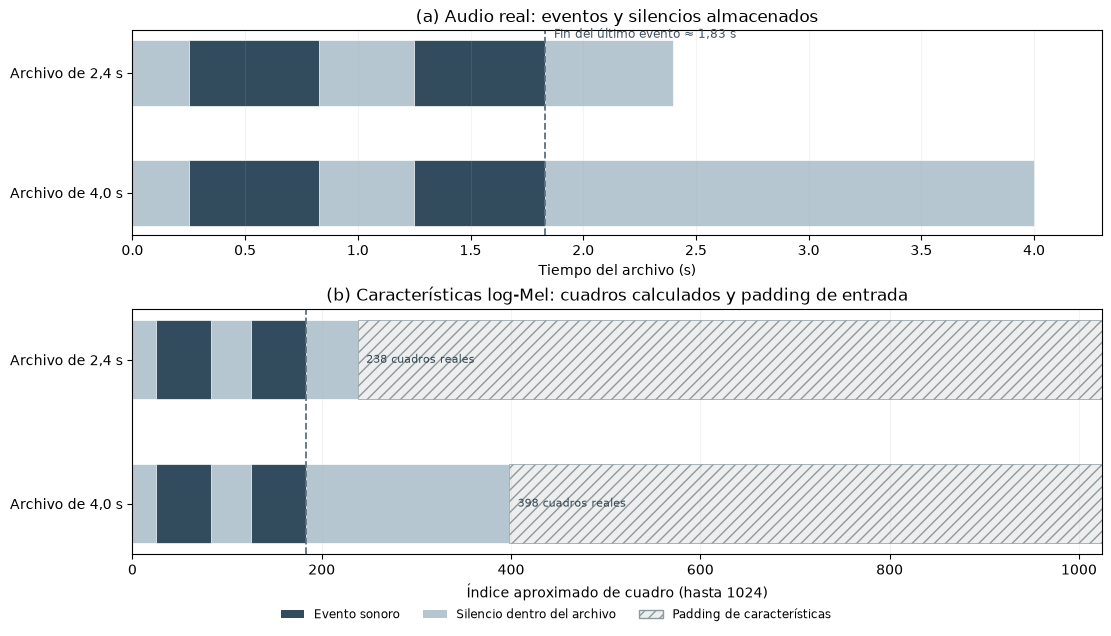

In [13]:
# Dos archivos con idénticos eventos, pero distinta cantidad de silencio al final.
x_mas_largo = np.concatenate([x_ab, np.zeros(int(1.6 * SR), dtype=np.float32)])
_, logmel_largo = calcular_logmel(x_mas_largo)
MAX_CUADROS = 1024
T_corto = logmel_ab.shape[1]
T_largo = logmel_largo.shape[1]

# Eventos nominales definidos por el generador (no son estimaciones automáticas).
EVENTOS = [(0.25, 0.25 + len(A)/SR), (1.25, 1.25 + len(B)/SR)]
FIN_EVENTOS = EVENTOS[-1][1]

def color_audio(seccion):
    return {'evento': '#324b5d', 'silencio': '#b6c6d0', 'padding': '#eeeeee'}[seccion]

print(f'Eventos: 0,25–{EVENTOS[0][1]:.2f} s y 1,25–{FIN_EVENTOS:.2f} s.')
for nombre, x, T in [('Archivo corto', x_ab, T_corto), ('Archivo largo', x_mas_largo, T_largo)]:
    print(f'{nombre}: {len(x)/SR:.1f} s de muestras reales; '
          f'{T} cuadros calculados y {MAX_CUADROS-T} de padding.')

fig, (a, b) = plt.subplots(2, 1, figsize=(11, 6.0),
                          gridspec_kw={'height_ratios': [1, 1.2]},
                          constrained_layout=True)

# Arriba: el audio existe solo hasta el final de cada archivo.
for y, dur, nombre in [(1, len(x_ab)/SR, 'Archivo de 2,4 s'),
                       (0, len(x_mas_largo)/SR, 'Archivo de 4,0 s')]:
    a.barh(y, dur, height=.55, color=color_audio('silencio'), edgecolor='white', lw=.5)
    for ini, fin in EVENTOS:
        a.barh(y, fin-ini, left=ini, height=.55,
               color=color_audio('evento'), edgecolor='white', lw=.5)
a.axvline(FIN_EVENTOS, ls='--', lw=1.3, color='#5b7180')
a.text(FIN_EVENTOS+.04, 1.32, 'Fin del último evento ≈ 1,83 s', fontsize=8.6,
       color='#3d5060', va='center')
a.set(xlim=(0, 4.3), yticks=[1, 0], yticklabels=['Archivo de 2,4 s', 'Archivo de 4,0 s'],
      xlabel='Tiempo del archivo (s)', title='(a) Audio real: eventos y silencios almacenados')
a.grid(axis='x', alpha=.15)

# Abajo: extensión del log-Mel calculado + padding de características hasta 1024.
# Las fronteras son aproximaciones en cuadros: cerca del inicio/final de un evento,
# la ventana de análisis se solapa con regiones vecinas.
for y, T in [(1, T_corto), (0, T_largo)]:
    b.barh(y, T, height=.55, color=color_audio('silencio'), edgecolor='white', lw=.5)
    for ini, fin in EVENTOS:
        ini_c=int(round(ini*SR/HOP)); fin_c=int(round(fin*SR/HOP))
        b.barh(y, fin_c-ini_c, left=ini_c, height=.55,
               color=color_audio('evento'), edgecolor='white', lw=.5)
    b.barh(y, MAX_CUADROS-T, left=T, height=.55, color=color_audio('padding'),
           edgecolor='#8b9a9f', lw=.5, hatch='///')
    b.text(T+9, y, f'{T} cuadros reales', fontsize=8, va='center', color='#334754')
b.axvline(int(round(FIN_EVENTOS*SR/HOP)), ls='--', lw=1.3, color='#5b7180')
b.set(xlim=(0, MAX_CUADROS), yticks=[1, 0], yticklabels=['Archivo de 2,4 s', 'Archivo de 4,0 s'],
      xlabel='Índice aproximado de cuadro (hasta 1024)',
      title='(b) Características log-Mel: cuadros calculados y padding de entrada')
b.grid(axis='x', alpha=.15)

from matplotlib.patches import Patch
leyenda=[Patch(facecolor=color_audio('evento'), label='Evento sonoro'),
         Patch(facecolor=color_audio('silencio'), label='Silencio dentro del archivo'),
         Patch(facecolor=color_audio('padding'), hatch='///', edgecolor='#8b9a9f',
               label='Padding de características')]
fig.legend(handles=leyenda, loc='lower center', bbox_to_anchor=(.5,-.045), ncol=3,
           frameon=False, fontsize=8.5)
plt.show()

**Figura de duración y padding.** Los dos archivos contienen los mismos eventos, terminados aproximadamente a los **1,83 s**. La diferencia posterior es **silencio que ya pertenece al audio**: el primero termina a los 2,4 s y el segundo a los 4,0 s. El *padding* de la representación comienza después de los cuadros efectivamente calculados para cada archivo.

> **Cuidado con las fronteras:** la clasificación de regiones en el panel (b) es **aproximada**. Cada cuadro espectral se calcula usando una ventana de 25 ms y, alrededor de una transición, la ventana puede incluir muestras de ambos lados.

### ¿Por qué nos debe importar?

El modelo puede recibir representaciones con diferentes proporciones de actividad, silencio y padding. **Aquí no afirmamos que AST cambie su predicción**; demostrarlo requeriría evaluar un AST real con un protocolo controlado.

**Pregunta para el curso:** si queremos comparar dos grabaciones de forma justa, ¿qué mantendríamos constante además de las frecuencias presentes: duración nominal, silencios, ganancia, escala de las características, padding…?


## 8. Cierre: ¿qué hemos aprendido?

Completa oralmente estas frases:

1. «Un espectrograma log-Mel muestra…»
2. «Un parche es…»
3. «Un embedding aprendido se diferencia de una proyección aleatoria porque…»
4. «La autoatención permite combinar información entre…»
5. «El padding no equivale exactamente a…»

### Una pregunta para continuar

Si A–B y B–A contienen los mismos eventos, pero en orden opuesto, ¿una representación intermedia debería conservar esa diferencia para permitir que un clasificador la reconozca? ¿Cómo podríamos comprobarlo?

**Recordatorio:** que un Transformer disponga de información posicional y autoatención **no demuestra** que haya aprendido una relación acústica particular, como el orden A–B frente a B–A. Eso exigiría pruebas con modelos entrenados y controles apropiados.

**Limitaciones de esta actividad:** no se descargaron pesos AST; no se entrenó ni evaluó ningún clasificador; la representación log-Mel visual es una aproximación pedagógica con Librosa, no una reproducción bit a bit del extractor AST; y la matriz de atención es una construcción matemática ilustrativa.

### Para explorar después de clase

- Gong, Y., Chung, Y.-A., & Glass, J. (2021). *AST: Audio Spectrogram Transformer*. Interspeech. https://www.isca-archive.org/interspeech_2021/gong21b_interspeech.html
- Código original de AST: https://github.com/YuanGongND/ast
- Documentación de AST y de su extractor: https://huggingface.co/docs/transformers/model_doc/audio-spectrogram-transformer

**ACUS220 · Escuchar, observar, representar y razonar.**